# Proyecto Final BI — Analista de Inversiones
**Crunchbase | Benchmark de startups y oportunidades de inversión**

Este notebook usa la base `build/crunchbase.duckdb` construida con `run_pipeline.py`. Analiza capital levantado, sectores, países, inversionistas y eventos de salida. Incluye un **ranking exploratorio**, no una predicción de rentabilidad.

**Alcance:** datos históricos de Crunchbase hasta diciembre de 2013; los montos de inversión no son ingresos ni ganancias. No se interpreta la adquisición o IPO como rendimiento positivo garantizado.

## 1. Configuración y conexión

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Localiza la base ya construida aunque el notebook esté en otra carpeta.
CANDIDATAS = [
    Path.cwd(), *Path.cwd().parents,
    Path.home() / "proyectofinal" / "proyecto_bi_codigo_ligero" / "proyecto_bi_crunchbase",
    Path.home() / "proyectofinal" / "proyecto_bi_crunchbase",
]
RAIZ = next((p for p in CANDIDATAS if (p / "build" / "crunchbase.duckdb").is_file()), None)
if RAIZ is None:
    raise FileNotFoundError("No encuentro build/crunchbase.duckdb. Colocá este notebook dentro de proyecto_bi_crunchbase/notebooks, donde corriste el pipeline.")
DB = RAIZ / "build" / "crunchbase.duckdb"
con = duckdb.connect(str(DB), read_only=True)
print("Conectado a:", DB)
print(con.execute("SELECT table_name FROM information_schema.tables WHERE table_schema='marts' ORDER BY 1").df().to_string(index=False))

Conectado a: C:\Users\Nany\proyectofinal\proyecto_bi_codigo_ligero\proyecto_bi_crunchbase\build\crunchbase.duckdb
                table_name
               dim_empresa
                 dim_fecha
         dim_inversionista
          fact_adquisicion
                  fact_ipo
                fact_ronda
puente_ronda_inversionista


## 2. Indicadores generales (KPI)

In [2]:
kpi = con.execute('''
SELECT
  (SELECT count(*) FROM marts.dim_empresa) AS empresas,
  (SELECT count(*) FROM marts.fact_ronda) AS rondas,
  (SELECT count(*) FROM marts.dim_inversionista) AS inversionistas,
  (SELECT round(sum(monto_usd)/1e9, 2) FROM marts.fact_ronda) AS capital_reportado_miles_millones_usd,
  (SELECT count(DISTINCT empresa_adquirida_key) FROM marts.fact_adquisicion) AS empresas_adquiridas,
  (SELECT count(DISTINCT empresa_key) FROM marts.fact_ipo) AS empresas_con_ipo
''').df()
display(kpi)

,empresas,rondas,inversionistas,capital_reportado_miles_millones_usd,empresas_adquiridas,empresas_con_ipo
0,196553,52518,16946,414.5,9394,1238


## 3. Benchmark por industria
Se cuenta cada ronda una sola vez, evitando duplicar montos por número de inversionistas.

,industria,empresas_con_rondas,rondas,capital_miles_millones_usd,monto_promedio_millones_usd
0,biotech,3105,5786,66.834,11.55
1,software,4252,6837,41.785,6.11
2,cleantech,989,1819,38.686,21.27
3,mobile,1855,3190,29.936,9.38
4,enterprise,1448,2906,21.361,7.35
5,web,2375,3602,18.924,5.25
6,ecommerce,1352,2103,17.715,8.42
7,hardware,973,1595,14.964,9.38
8,games_video,1171,1837,14.717,8.01
9,medical,660,1359,13.236,9.74


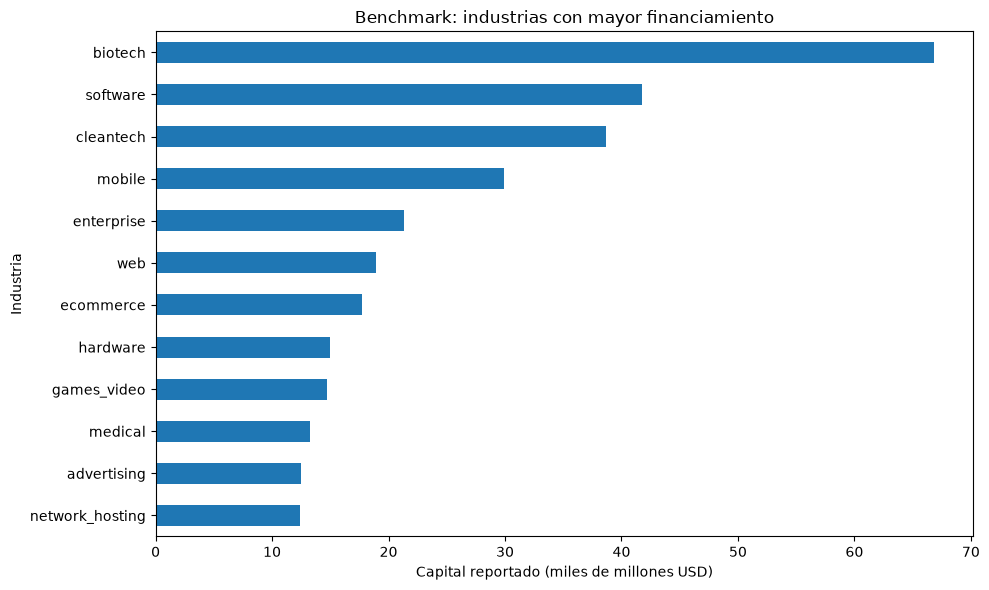

In [3]:
sectores = con.execute('''
SELECT e.industria,
       count(DISTINCT e.empresa_key) AS empresas_con_rondas,
       count(*) AS rondas,
       round(sum(r.monto_usd)/1e9, 3) AS capital_miles_millones_usd,
       round(avg(r.monto_usd)/1e6, 2) AS monto_promedio_millones_usd
FROM marts.fact_ronda r
JOIN marts.dim_empresa e ON e.empresa_key=r.empresa_key
WHERE r.monto_usd IS NOT NULL AND e.industria <> 'sin_dato'
GROUP BY 1
HAVING count(DISTINCT e.empresa_key) >= 30
ORDER BY capital_miles_millones_usd DESC
LIMIT 12
''').df()
display(sectores)
ax = sectores.sort_values('capital_miles_millones_usd').plot.barh(
    x='industria', y='capital_miles_millones_usd', legend=False, figsize=(10,6))
ax.set(xlabel='Capital reportado (miles de millones USD)', ylabel='Industria',
       title='Benchmark: industrias con mayor financiamiento')
plt.tight_layout()
plt.show()

## 4. Benchmark por país

,pais,empresas_financiadas,rondas,capital_miles_millones_usd
0,USA,18146,33287,310.497
1,GBR,1718,2563,19.068
2,CHN,273,367,10.682
3,CAN,874,1351,9.953
4,IND,399,512,6.141
5,DEU,465,648,5.811
6,FRA,642,883,4.600
7,ISR,467,708,4.480
8,CHE,142,221,2.836
9,NLD,168,243,2.376


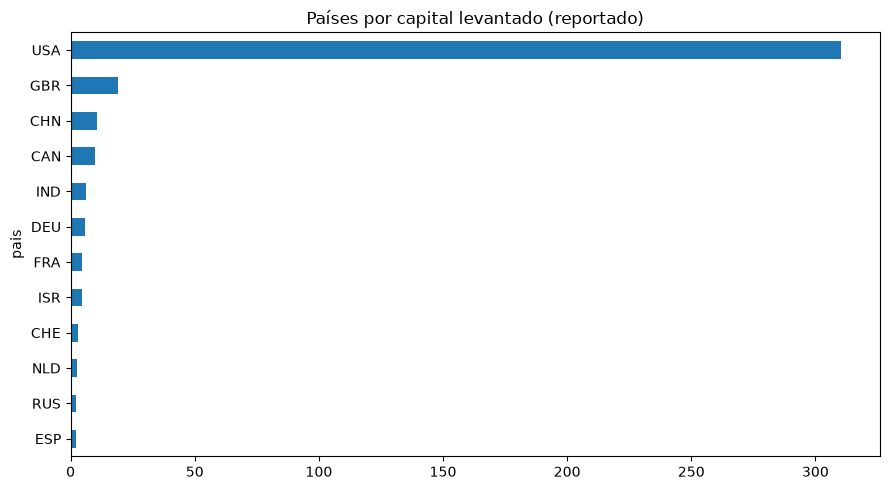

In [4]:
paises = con.execute('''
SELECT e.pais,
       count(DISTINCT e.empresa_key) AS empresas_financiadas,
       count(*) AS rondas,
       round(sum(r.monto_usd)/1e9, 3) AS capital_miles_millones_usd
FROM marts.fact_ronda r
JOIN marts.dim_empresa e USING (empresa_key)
WHERE r.monto_usd IS NOT NULL AND e.pais <> 'sin_dato'
GROUP BY 1 ORDER BY capital_miles_millones_usd DESC LIMIT 12
''').df()
display(paises)
paises.sort_values('capital_miles_millones_usd').plot.barh(
    x='pais', y='capital_miles_millones_usd', legend=False, figsize=(9,5),
    title='Países por capital levantado (reportado)')
plt.tight_layout()
plt.show()

## 5. Startups con mayor financiamiento histórico
Este listado **no** equivale a las empresas más rentables.

In [5]:
empresas = con.execute('''
SELECT e.empresa_key, e.nombre, e.industria, e.pais,
       count(*) AS rondas,
       round(sum(r.monto_usd)/1e6, 2) AS capital_millones_usd,
       count(DISTINCT CASE WHEN r.n_inversionistas > 0 THEN r.ronda_id END) AS rondas_con_inversionistas
FROM marts.fact_ronda r
JOIN marts.dim_empresa e USING (empresa_key)
WHERE r.monto_usd IS NOT NULL
GROUP BY 1,2,3,4
ORDER BY capital_millones_usd DESC LIMIT 20
''').df()
display(empresas.drop(columns='empresa_key'))

,nombre,industria,pais,rondas,capital_millones_usd,rondas_con_inversionistas
0,Clearwire,mobile,USA,4,5700.00,4
1,"Verizon Communications, Inc.",mobile,USA,2,3985.05,1
2,sigmacare,health,USA,1,2600.00,1
3,Facebook,social,USA,11,2425.70,11
4,Carestream,biotech,USA,1,2400.00,0
5,Solyndra,manufacturing,USA,9,1765.50,3
6,Fisker Automotive,automotive,USA,8,1451.00,5
7,AndrewBurnett.com Ltd,consulting,GBR,1,1314.20,1
8,O3b Networks,enterprise,GBR,5,1270.28,2
9,Terra-Gen Power,cleantech,USA,1,1200.00,0


## 6. Inversionistas más activos
La actividad se mide por número de empresas y rondas; no representa retornos financieros.

In [6]:
inversionistas = con.execute('''
SELECT nombre, tipo_inversionista, pais, n_empresas, n_rondas
FROM marts.dim_inversionista
ORDER BY n_empresas DESC, n_rondas DESC LIMIT 20
''').df()
display(inversionistas)

,nombre,tipo_inversionista,pais,n_empresas,n_rondas
0,Y Combinator,empresa,USA,457,476
1,SV Angel,organizacion_financiera,USA,441,483
2,Intel Capital,organizacion_financiera,USA,381,527
3,New Enterprise Associates,organizacion_financiera,USA,318,510
4,500 Startups,organizacion_financiera,USA,315,364
5,Sequoia Capital,organizacion_financiera,USA,308,506
6,Accel Partners,organizacion_financiera,USA,286,476
7,Draper Fisher Jurvetson (DFJ),organizacion_financiera,USA,273,460
8,Kleiner Perkins Caufield & Byers,organizacion_financiera,USA,269,474
9,Techstars,empresa,USA,268,297


## 7. Salidas históricas por industria (adquisición o IPO)
La proporción es descriptiva y **no** controla por edad de la empresa, censura temporal ni diferencias de cobertura.

In [7]:
salidas = con.execute('''
WITH a AS (SELECT DISTINCT empresa_adquirida_key AS empresa_key FROM marts.fact_adquisicion),
     i AS (SELECT DISTINCT empresa_key FROM marts.fact_ipo)
SELECT e.industria, count(*) AS empresas,
       count(*) FILTER (WHERE a.empresa_key IS NOT NULL OR i.empresa_key IS NOT NULL) AS empresas_con_salida,
       round(100.0 * count(*) FILTER (WHERE a.empresa_key IS NOT NULL OR i.empresa_key IS NOT NULL)
             / nullif(count(*),0), 2) AS porcentaje_con_salida
FROM marts.dim_empresa e
LEFT JOIN a USING (empresa_key)
LEFT JOIN i USING (empresa_key)
WHERE e.industria <> 'sin_dato'
GROUP BY 1 HAVING count(*) >= 100
ORDER BY porcentaje_con_salida DESC
''').df()
display(salidas.head(15))

,industria,empresas,empresas_con_salida,porcentaje_con_salida
0,semiconductor,696,207,29.74
1,biotech,4430,702,15.85
2,security,1171,148,12.64
3,enterprise,4441,463,10.43
4,hardware,2951,290,9.83
5,network_hosting,2350,231,9.83
6,messaging,296,29,9.80
7,software,17922,1580,8.82
8,cleantech,1940,171,8.81
9,public_relations,2846,245,8.61


## 8. Ranking exploratorio de startups (benchmark)
**Regla ilustrativa, no modelo predictivo:** entre empresas con al menos 2 rondas y capital conocido, se asigna una puntuación por percentiles de: capital acumulado (40%), cantidad de rondas (35%) y cantidad de rondas con inversionistas identificados (25%). La muestra es histórica y puede contener empresas ya adquiridas o públicas. **No es una recomendación de compra ni una estimación de probabilidad de éxito.**

In [8]:
universo = con.execute('''
SELECT e.nombre, e.industria, e.pais,
       count(*) AS rondas,
       sum(r.monto_usd) AS capital_usd,
       count(*) FILTER (WHERE r.n_inversionistas > 0) AS rondas_con_inversionistas
FROM marts.fact_ronda r
JOIN marts.dim_empresa e USING (empresa_key)
WHERE r.monto_usd IS NOT NULL AND r.monto_usd > 0
GROUP BY e.empresa_key, e.nombre, e.industria, e.pais
HAVING count(*) >= 2
''').df()
for campo in ['capital_usd', 'rondas', 'rondas_con_inversionistas']:
    universo['p_'+campo] = universo[campo].rank(pct=True)
universo['score_exploratorio'] = (100 * (
    0.40*universo['p_capital_usd'] +
    0.35*universo['p_rondas'] +
    0.25*universo['p_rondas_con_inversionistas'])).round(1)
ranking = universo.sort_values('score_exploratorio', ascending=False).head(10).copy()
ranking['capital_millones_usd'] = (ranking['capital_usd']/1e6).round(2)
display(ranking[['nombre','industria','pais','rondas','capital_millones_usd',
                 'rondas_con_inversionistas','score_exploratorio']])
print("Empresas evaluadas:", len(universo))

,nombre,industria,pais,rondas,capital_millones_usd,rondas_con_inversionistas,score_exploratorio
9713,Tesla Motors,automotive,USA,11,823.00,10,99.9
2702,Facebook,social,USA,11,2425.70,11,99.9
8570,SolarCity,cleantech,USA,12,789.04,8,99.9
1409,LivingSocial,ecommerce,USA,9,924.50,8,99.7
8723,Deem,ecommerce,USA,10,466.91,9,99.7
7785,Intrexon Corporation,biotech,USA,11,437.59,7,99.7
3219,Fab.com,ecommerce,USA,11,336.32,11,99.7
5063,Box,network_hosting,USA,9,408.60,9,99.6
7877,SoloPower,cleantech,USA,10,458.09,6,99.5
1447,Chegg,education,USA,10,252.30,10,99.5


Empresas evaluadas: 10106


## 9. Conclusiones
Al ejecutar las celdas, describí **los valores efectivamente obtenidos**.

- **Benchmark sectorial:** comparar qué industrias concentran el capital reportado y si el promedio por ronda coincide con el volumen total.
- **Benchmark geográfico:** identificar la concentración de financiamiento por país, recordando que puede existir sesgo de cobertura.
- **Startups:** distinguir *capital levantado* de *rentabilidad*. Una empresa muy financiada no necesariamente es una buena inversión.
- **Inversionistas:** el número de empresas participadas refleja actividad, no rendimiento.
- **Salidas:** adquisición o IPO es un evento observable, no prueba de ganancia para todos los inversionistas.
- **Ranking:** usarlo solo para seleccionar empresas que merecen investigación adicional (*due diligence*). Antes de invertir harían falta ingresos, márgenes, valoración, deuda, flujo de caja, riesgos y datos actualizados.

**Limitaciones:** fuente histórica hasta 2013, valores desconocidos, cobertura incompleta y posibles sesgos. No hay validación de un modelo de predicción de rentabilidad.

**Nota de reproducibilidad:** este notebook consulta DuckDB local. Publicar en NeonDB es un paso separado del proyecto general.